# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [17]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [18]:
df = pd.read_csv("/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [19]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [20]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [21]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

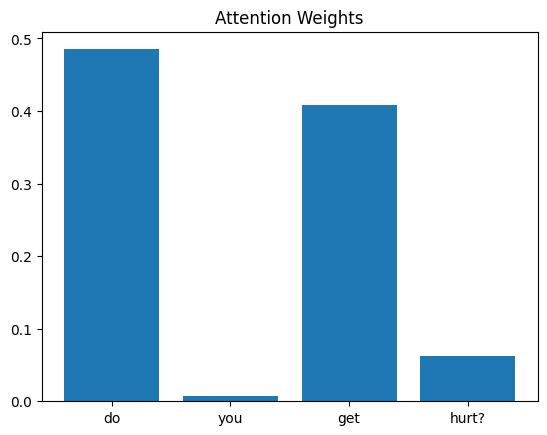

In [22]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest Attention Word: do
Attention Weight: 0.4851


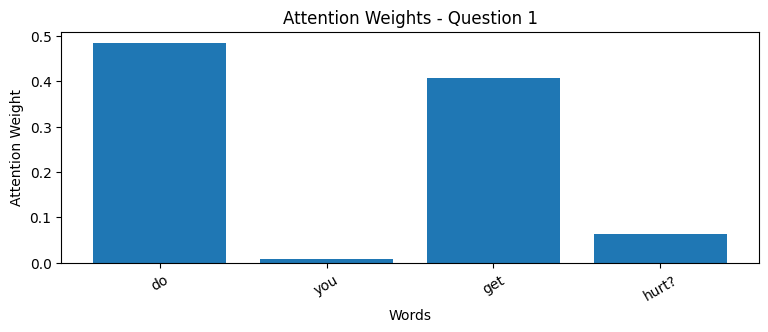

Observation: The model focuses most on 'do'.
--------------------------------------------------
Question: are you old?
Highest Attention Word: are
Attention Weight: 0.6517


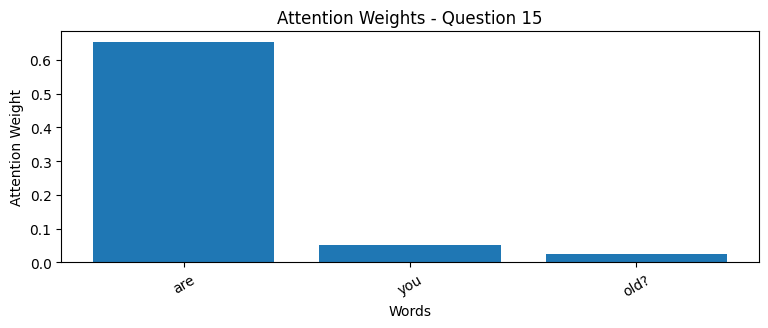

Observation: The model focuses most on 'are'.
--------------------------------------------------
Question: will you ask me anything about myself
Highest Attention Word: about
Attention Weight: 0.6157


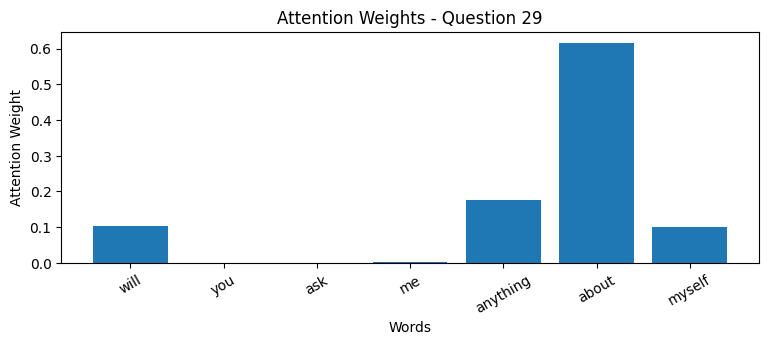

Observation: The model focuses most on 'about'.
--------------------------------------------------
Overall Observation:
The model does not always focus on the most meaningful words.
Some common words receive higher attention weights,
showing that high attention does not necessarily mean
high semantic importance.


In [30]:
# Task 1: Visualize attention for three questions

question_indices = [0, 14, 28]

model.eval()

for i in question_indices:
    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention = weights[0, :len(words)].tolist()
    highest_idx = attention.index(max(attention))
    highest_word = words[highest_idx]

    print("Question:", question)
    print("Highest Attention Word:", highest_word)
    print("Attention Weight:", round(attention[highest_idx], 4))

    plt.figure(figsize=(9, 3))
    plt.bar(words, attention)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=30)
    plt.show()

    print("Observation:",
          f"The model focuses most on '{highest_word}'.")
    print("-" * 50)

print("Overall Observation:")
print("The model does not always focus on the most meaningful words.")
print("Some common words receive higher attention weights,")
print("showing that high attention does not necessarily mean")
print("high semantic importance.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: do you ever breathe
Highest Attention Word: do
Attention Weight: 0.6996


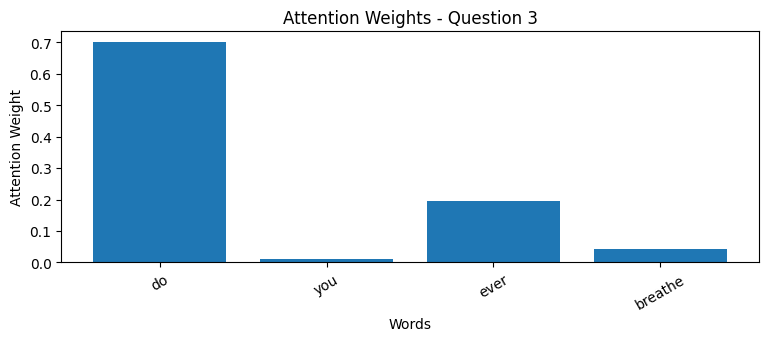

Question: can you breathe
Highest Attention Word: can
Attention Weight: 0.5524


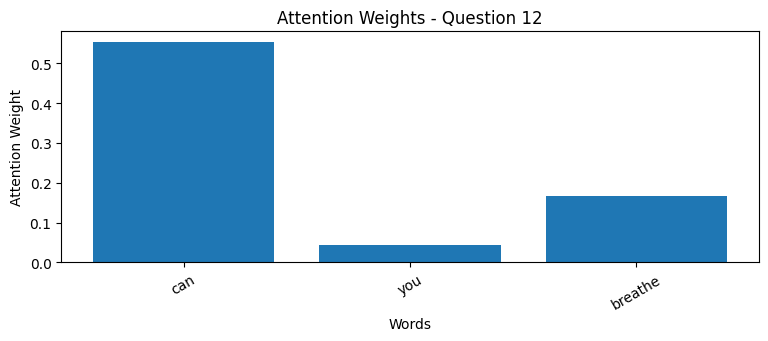

Comparison:
The model focuses on different words in the two questions.

Conclusion:
Although both questions have similar meanings,
their attention distributions can be different.
This suggests that attention is influenced by
word choice and sentence structure.


In [31]:
# Task 2: Compare attention for similar questions

question_indices = [2, 11]
highest_words = []

model.eval()

for i in question_indices:
    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention = weights[0, :len(words)].tolist()
    highest_idx = attention.index(max(attention))
    highest_word = words[highest_idx]

    highest_words.append(highest_word)

    print("Question:", question)
    print("Highest Attention Word:", highest_word)
    print("Attention Weight:", round(attention[highest_idx], 4))

    plt.figure(figsize=(9, 3))
    plt.bar(words, attention)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=30)
    plt.show()

print("Comparison:")

if highest_words[0] == highest_words[1]:
    print("The model focuses on the same word in both questions.")
else:
    print("The model focuses on different words in the two questions.")

print("\nConclusion:")
print("Although both questions have similar meanings,")
print("their attention distributions can be different.")
print("This suggests that attention is influenced by")
print("word choice and sentence structure.")